# 03 – Exploratory Data Analysis (EDA)

**Project:** Marketing Mix Modelling & Budget Optimisation (Sri Lankan FMCG brand)

**Input:** `data/processed/feature_engineered_marketing_mix_data.csv`

**Output:** figures in `outputs/figures/`, `vif_table.csv` in `outputs/tables/`

**Questions this notebook answers**

1. How have sales behaved over 36 months (trend, peaks, seasonality)?
2. How is the budget split across the 6 channels and how did it change?
3. Which channels / external factors move with sales?
4. Are the channels correlated with each other (multicollinearity → VIF)?
5. Is there a hint of diminishing returns or delayed (carry-over) effects?

## 0. Setup

In [ ]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold"})

ROOT = Path("..")
PROC = ROOT / "data" / "processed"
DATA = next(p for p in [PROC / "feature_engineered_marketing_mix_data.csv", PROC / "model_data.csv"] if p.exists())
print("Using:", DATA.name)
FIG  = ROOT / "outputs" / "figures";  FIG.mkdir(parents=True, exist_ok=True)
TAB  = ROOT / "outputs" / "tables";   TAB.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    print("saved ->", FIG / f"{name}.png")

Using: feature_engineered_marketing_mix_data.csv


## 1. Load data & first look

In [ ]:
df = pd.read_csv(DATA)

DATE = next(c for c in ["date", "month", "Date", "Month"] if c in df.columns)
df[DATE] = pd.to_datetime(df[DATE])
df = df.sort_values(DATE).reset_index(drop=True)

TARGET = "sales_revenue_lkr"
CHANNELS = ["tv_spend_lkr", "facebook_instagram_spend_lkr", "google_search_spend_lkr",
            "youtube_spend_lkr", "radio_spend_lkr", "outdoor_spend_lkr"]
EXTERNAL = ["average_price_index", "promotion_discount_pct", "competitor_pressure_index_0_100",
            "economic_sentiment_index_0_100", "lkr_usd_exchange_rate", "inflation_proxy_index",
            "seasonal_demand_index", "public_holiday_count"]

CHANNELS = [c for c in CHANNELS if c in df.columns]
EXTERNAL = [c for c in EXTERNAL if c in df.columns]
NICE = {c: c.replace("_spend_lkr", "").replace("_0_100", "").replace("_", " ").title().replace("Tv", "TV").replace("Lkr Usd", "LKR/USD") for c in CHANNELS + EXTERNAL}

print("Shape:", df.shape, "| Period:", df[DATE].min().date(), "to", df[DATE].max().date())
df.head()

Shape: (36, 44) | Period: 2023-01-01 to 2025-12-01


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


In [3]:
# data health check
print("Missing values :", int(df.isna().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
print("Months in order, no gaps:", df[DATE].diff().dropna().dt.days.between(28, 31).all())
const = [c for c in df.columns if df[c].nunique() <= 1]
print("Constant columns:", const)
df.describe().T.round(2)

Missing values : 0
Duplicate rows : 0
Months in order, no gaps: True
Constant columns: ['country', 'brand_category', 'region_scope', 'data_type']


,count,mean,min,25%,50%,75%,max,std
month,36,2024-06-16 02:40:00,2023-01-01 00:00:00,2023-09-23 12:00:00,2024-06-16 00:00:00,2025-03-08 18:00:00,2025-12-01 00:00:00,NaN
tv_spend_lkr,36.0,4360117.833333,2638465.0,3846029.25,4352655.0,4920907.0,6020432.0,864146.534337
facebook_instagram_spend_lkr,36.0,4398433.805556,3067341.0,3732281.5,4490287.5,4952397.75,6030031.0,773682.579161
google_search_spend_lkr,36.0,3315364.861111,2162014.0,2907149.0,3249230.0,3907576.0,5096864.0,719645.721645
youtube_spend_lkr,36.0,2219825.805556,1476724.0,1882028.5,2160447.5,2458514.75,3178264.0,445606.923387
radio_spend_lkr,36.0,1669666.638889,1217450.0,1459317.0,1653602.5,1898464.25,2169012.0,272898.241938
outdoor_spend_lkr,36.0,2612716.722222,1727984.0,2052059.0,2516048.0,3176403.0,3690845.0,632527.382764
total_ad_spend_lkr,36.0,18576125.666667,13534423.0,15970314.0,19091334.5,21088035.75,22733821.0,2803201.967325
sales_revenue_lkr,36.0,85118577.246111,70114068.63,81342988.0,84759517.0,88828934.25,100057853.6,7509466.649595
units_sold,36.0,152975.5,112715.0,137041.25,152151.0,169776.25,203031.0,24743.534398


## 2. Sales trend
What to look for: is revenue going up over time? Which months peak? Is there a repeating yearly shape?

saved -> ..\outputs\figures\01_sales_trend.png


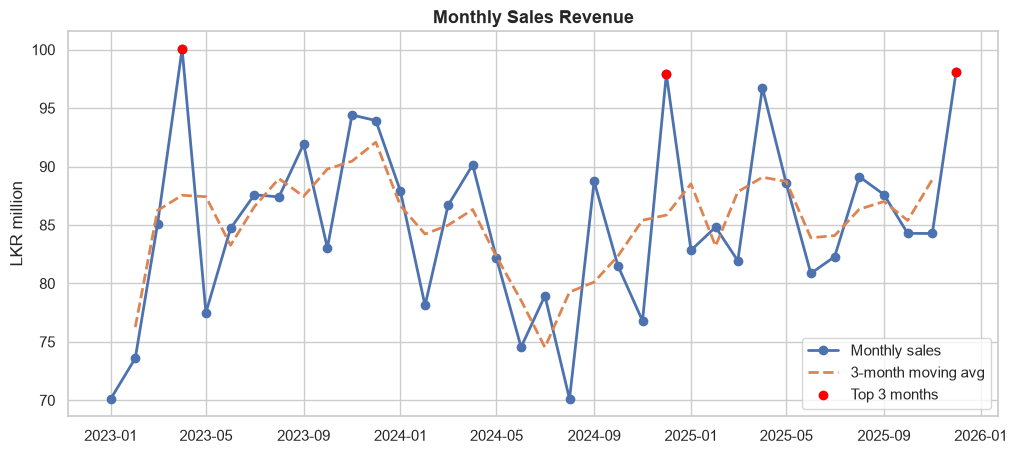

          sales_lkr  yoy_growth_%
month                            
2023   1.029304e+09           NaN
2024   9.935178e+08          -3.5
2025   1.041447e+09           4.8

Top 3 months:
      month  sales_revenue_lkr
2023-04-01        100057853.6
2025-12-01         98107722.0
2024-12-01         97913978.0


In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df[DATE], df[TARGET] / 1e6, marker="o", lw=2, label="Monthly sales")
ax.plot(df[DATE], (df[TARGET] / 1e6).rolling(3, center=True).mean(), lw=2, ls="--", label="3-month moving avg")
top = df.nlargest(3, TARGET)
ax.scatter(top[DATE], top[TARGET] / 1e6, color="red", zorder=5, label="Top 3 months")
ax.set(title="Monthly Sales Revenue", xlabel="", ylabel="LKR million"); ax.legend()
save(fig, "01_sales_trend"); plt.show()

yearly = df.groupby(df[DATE].dt.year)[TARGET].sum().to_frame("sales_lkr")
yearly["yoy_growth_%"] = yearly["sales_lkr"].pct_change() * 100
print(yearly.round(1))
print("\nTop 3 months:\n", top[[DATE, TARGET]].to_string(index=False))

## 3. Media spend trends (per channel)

saved -> ..\outputs\figures\02_spend_trends.png


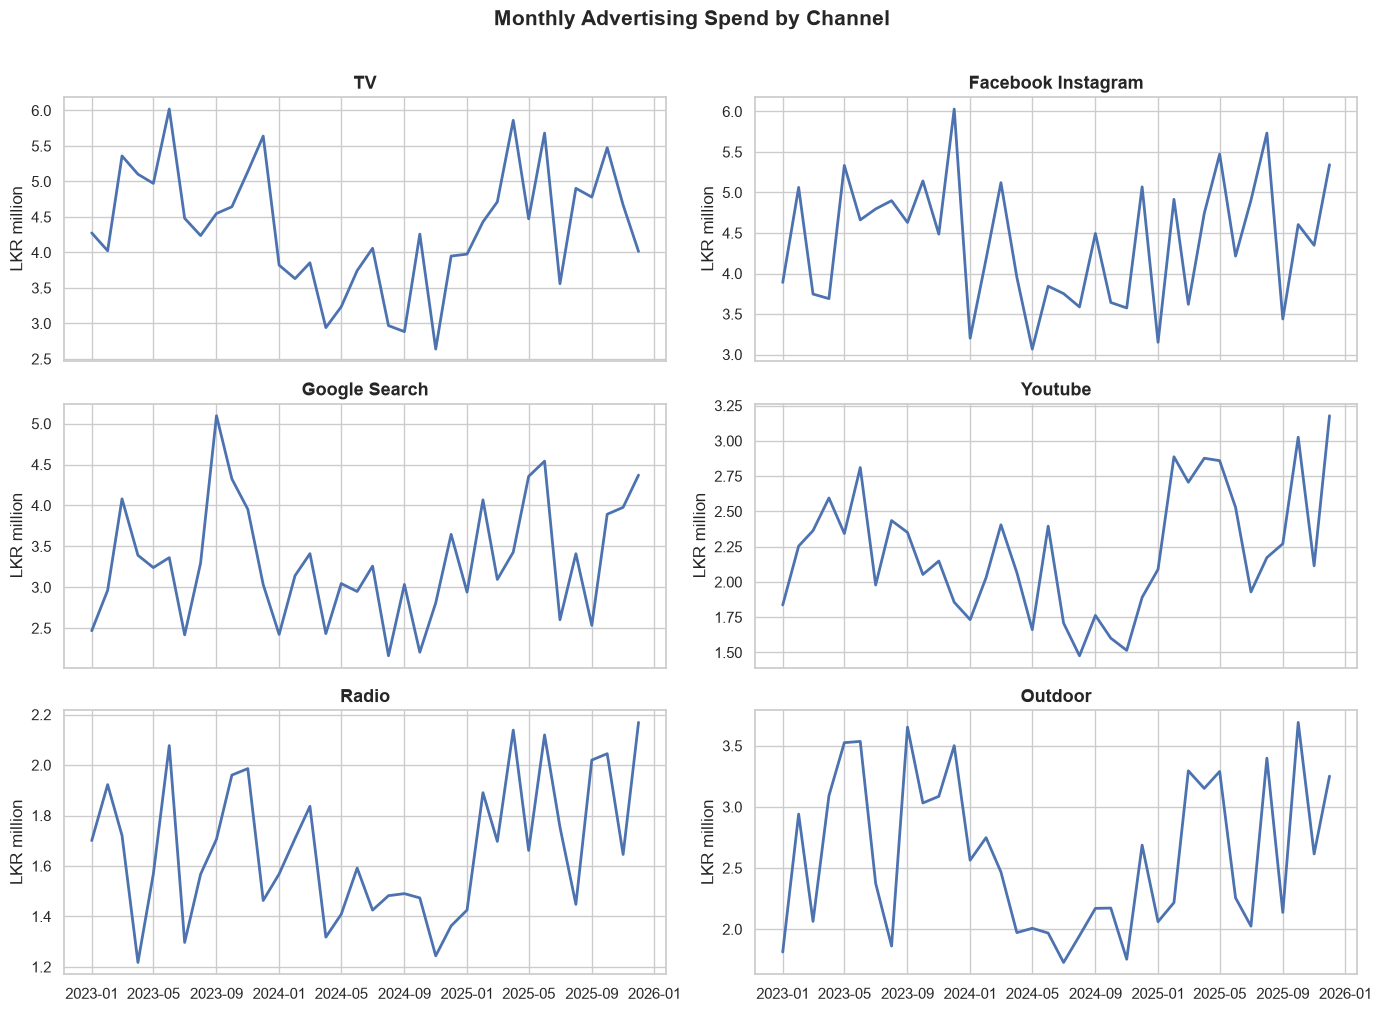

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, ch in zip(axes.ravel(), CHANNELS):
    ax.plot(df[DATE], df[ch] / 1e6, lw=2)
    ax.set_title(NICE[ch]); ax.set_ylabel("LKR million")
fig.suptitle("Monthly Advertising Spend by Channel", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout(); save(fig, "02_spend_trends"); plt.show()

## 4. Spend mix – where does the budget go?

saved -> ..\outputs\figures\03_spend_mix.png


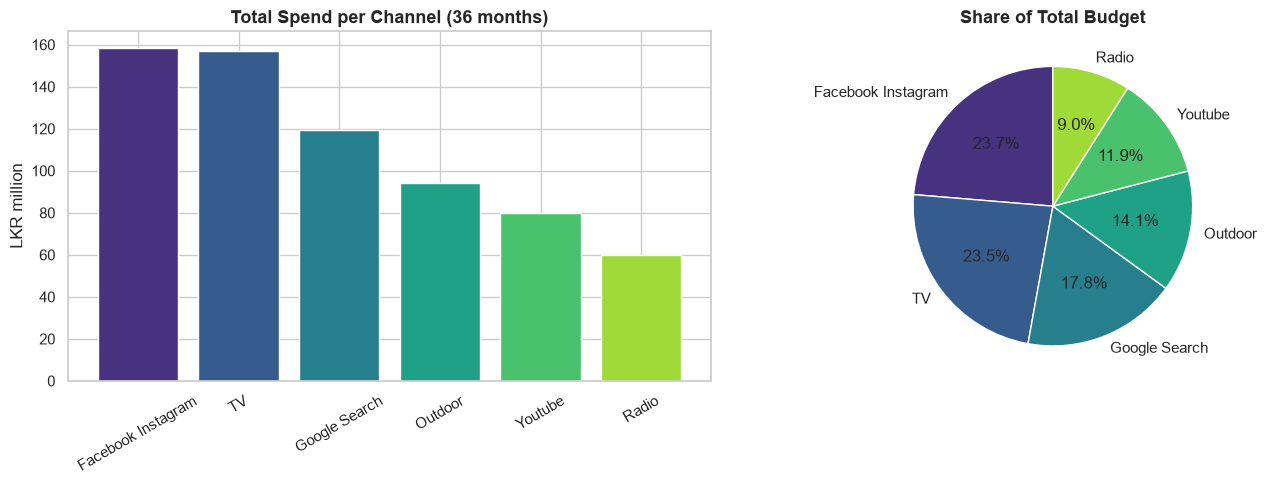

saved -> ..\outputs\figures\04_spend_mix_by_year.png


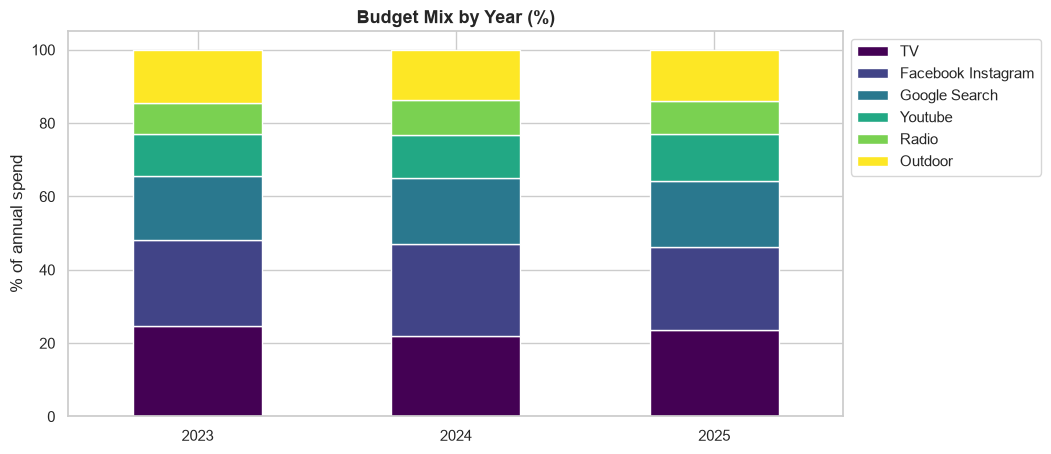

Facebook Instagram    23.7
TV                    23.5
Google Search         17.8
Outdoor               14.1
Youtube               11.9
Radio                  9.0
dtype: float64


In [6]:
tot = df[CHANNELS].sum().sort_values(ascending=False)
share = tot / tot.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar([NICE[c] for c in tot.index], tot / 1e6, color=sns.color_palette("viridis", len(tot)))
axes[0].set(title="Total Spend per Channel (36 months)", ylabel="LKR million")
axes[0].tick_params(axis="x", rotation=30)
axes[1].pie(share, labels=[NICE[c] for c in share.index], autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("viridis", len(tot)))
axes[1].set_title("Share of Total Budget")
fig.tight_layout(); save(fig, "03_spend_mix"); plt.show()

# how the mix changes year by year
mix_year = df.groupby(df[DATE].dt.year)[CHANNELS].sum()
mix_year_pct = mix_year.div(mix_year.sum(axis=1), axis=0) * 100
ax = mix_year_pct.rename(columns=NICE).plot(kind="bar", stacked=True, figsize=(10, 5), colormap="viridis")
ax.set(title="Budget Mix by Year (%)", xlabel="", ylabel="% of annual spend"); ax.legend(bbox_to_anchor=(1, 1))
plt.xticks(rotation=0); save(ax.figure, "04_spend_mix_by_year"); plt.show()
print(share.round(1).rename(NICE))

## 5. Correlation analysis

Reading the heatmap: values near +1 / −1 = strong relationship.

 Two things matter:

**(a)** which variables correlate with sales, 

**(b)** which *channels* correlate with each other (multicollinearity).


saved -> ..\outputs\figures\05_correlation_heatmap.png


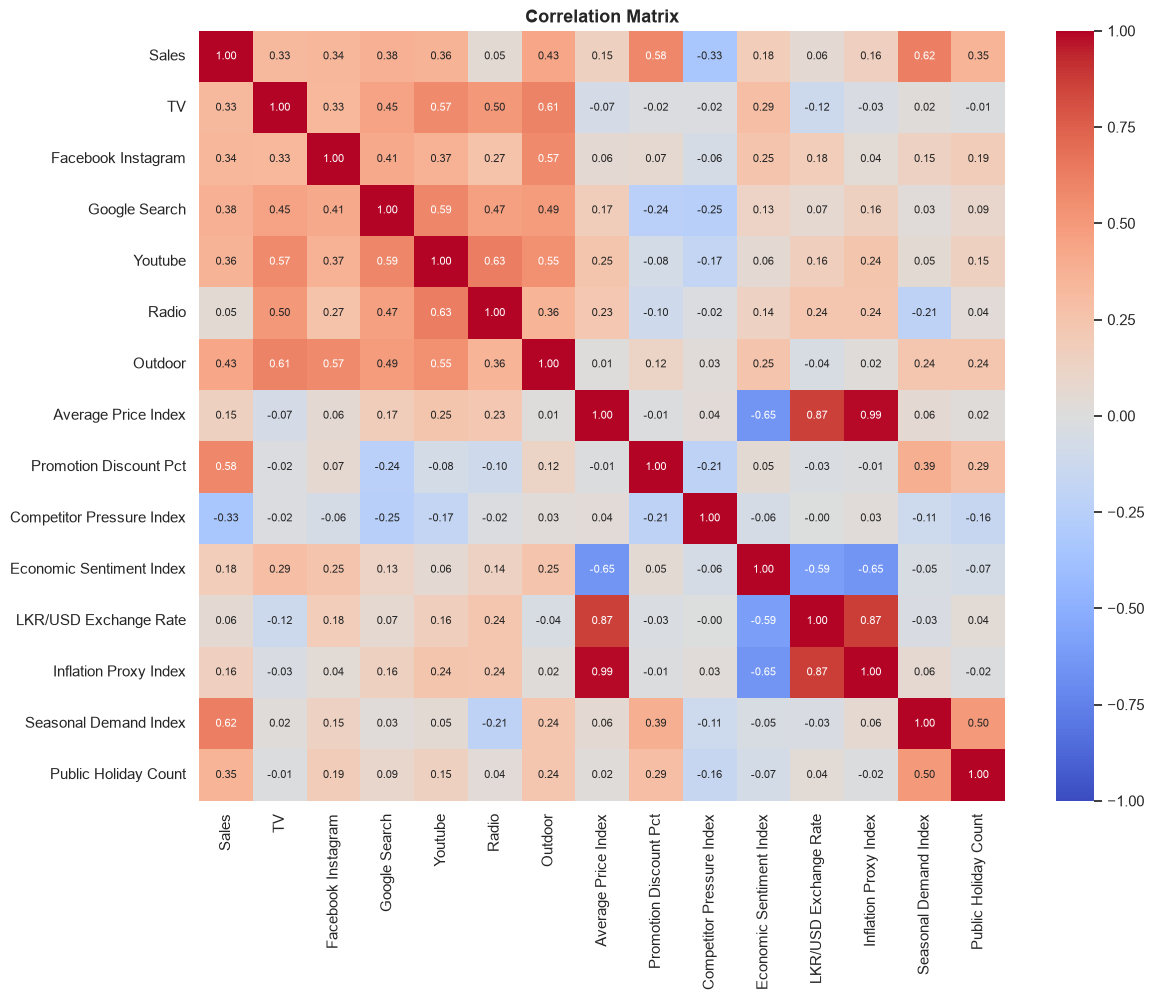

saved -> ..\outputs\figures\06_corr_with_sales.png


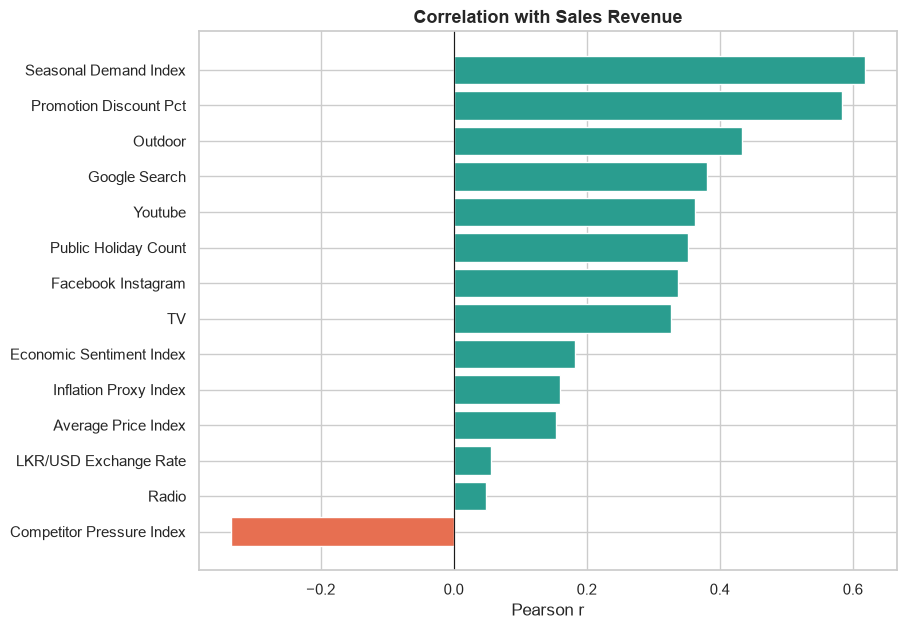

Seasonal Demand Index        0.62
Promotion Discount Pct       0.58
Outdoor                      0.43
Google Search                0.38
Youtube                      0.36
Public Holiday Count         0.35
Facebook Instagram           0.34
TV                           0.33
Economic Sentiment Index     0.18
Inflation Proxy Index        0.16
Average Price Index          0.15
LKR/USD Exchange Rate        0.06
Radio                        0.05
Competitor Pressure Index   -0.33
Name: sales_revenue_lkr, dtype: float64


In [7]:
core = [TARGET] + CHANNELS + EXTERNAL
corr = df[core].corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr.rename(index=NICE, columns=NICE | {TARGET: "Sales"}).rename(index={TARGET: "Sales"}),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation Matrix"); save(fig, "05_correlation_heatmap"); plt.show()

s = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([NICE[i] for i in s.index], s.values, color=np.where(s.values > 0, "#2a9d8f", "#e76f51"))
ax.axvline(0, color="k", lw=0.8); ax.set(title="Correlation with Sales Revenue", xlabel="Pearson r")
save(fig, "06_corr_with_sales"); plt.show()
print(s.sort_values(ascending=False).round(2).rename(NICE))

In [ ]:
# strongest channel-vs-channel correlations (multicollinearity warning)

cc = df[CHANNELS].corr().where(np.triu(np.ones((len(CHANNELS),) * 2), 1).astype(bool)).stack()
cc = cc.rename_axis(["ch1", "ch2"]).reset_index(name="r")
cc["abs_r"] = cc["r"].abs(); cc = cc.sort_values("abs_r", ascending=False)
cc[["ch1", "ch2"]] = cc[["ch1", "ch2"]].apply(lambda c: c.map(NICE))
cc.head(5).drop(columns="abs_r").round(2)

,ch1,ch2,r
22,Youtube,Radio,0.63
5,TV,Outdoor,0.61
15,Google Search,Youtube,0.59
3,TV,Youtube,0.57
11,Facebook Instagram,Outdoor,0.57


## 6. Channel spend vs sales (diminishing returns hint)
A straight line = constant returns. 
A line that flattens at high spend = **diminishing returns** (saturation).
Both a linear fit and a LOWESS curve are drawn.

saved -> ..\outputs\figures\07_spend_vs_sales.png


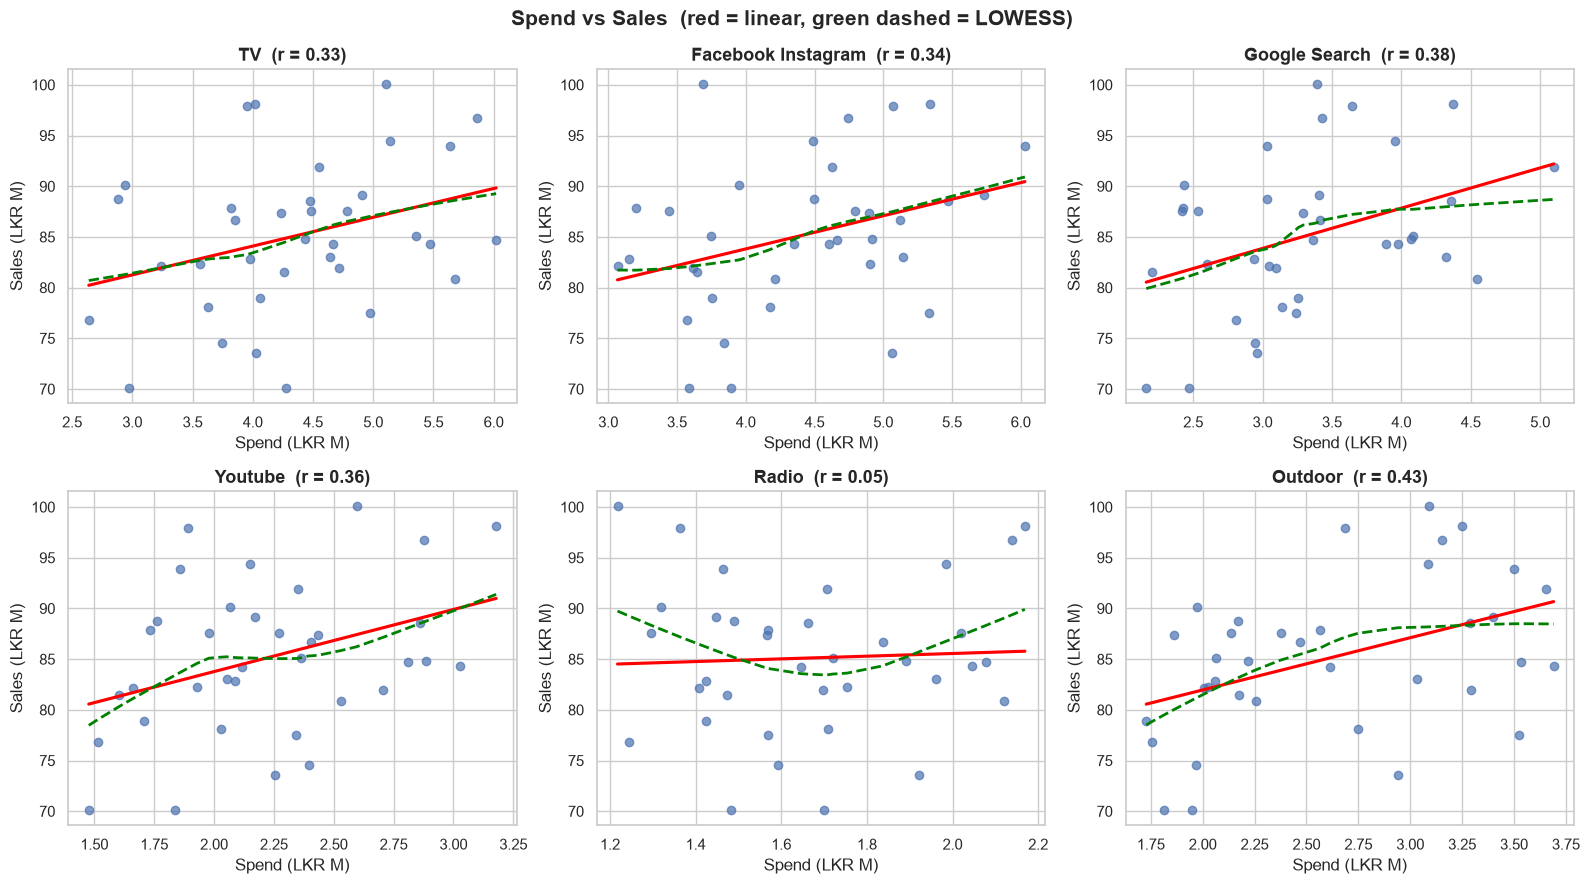

In [9]:
import statsmodels.api as sm
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, ch in zip(axes.ravel(), CHANNELS):
    x, y = df[ch] / 1e6, df[TARGET] / 1e6
    sns.regplot(x=x, y=y, ax=ax, scatter_kws={"alpha": .7}, line_kws={"color": "red"}, ci=None)
    lo = sm.nonparametric.lowess(y, x, frac=0.8)
    ax.plot(lo[:, 0], lo[:, 1], color="green", lw=2, ls="--")
    r = df[[ch, TARGET]].corr().iloc[0, 1]
    ax.set(title=f"{NICE[ch]}  (r = {r:.2f})", xlabel="Spend (LKR M)", ylabel="Sales (LKR M)")
fig.suptitle("Spend vs Sales  (red = linear, green dashed = LOWESS)", fontsize=15, fontweight="bold")
fig.tight_layout(); save(fig, "07_spend_vs_sales"); plt.show()

## 7. External factors vs sales

saved -> ..\outputs\figures\08_external_vs_sales.png


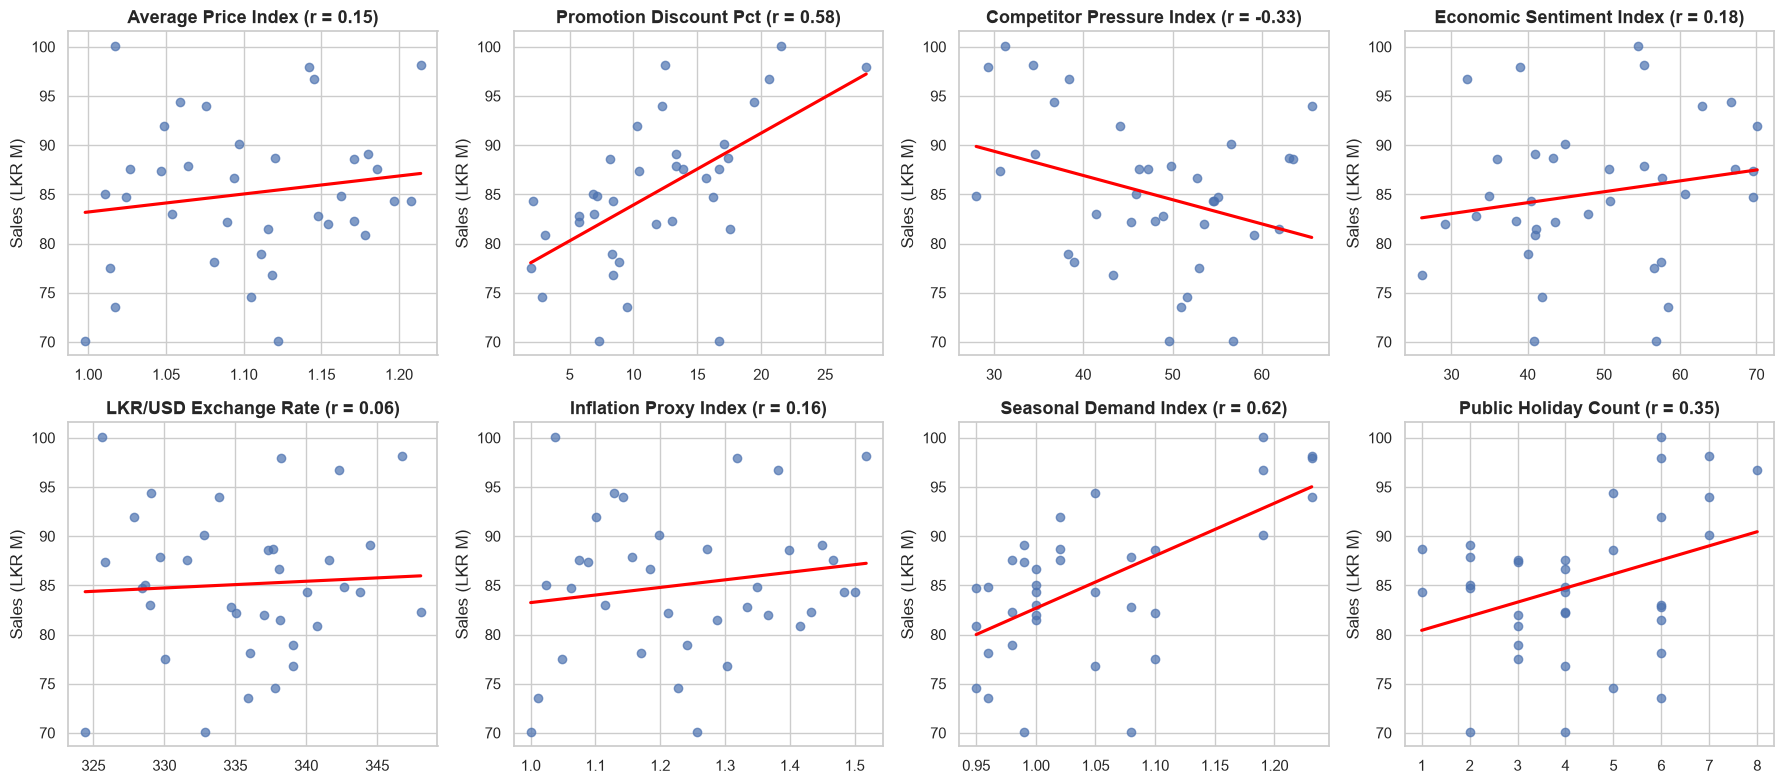

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), EXTERNAL):
    sns.regplot(x=df[f], y=df[TARGET] / 1e6, ax=ax, ci=None, scatter_kws={"alpha": .7}, line_kws={"color": "red"})
    r = df[[f, TARGET]].corr().iloc[0, 1]
    ax.set(title=f"{NICE[f]} (r = {r:.2f})", xlabel="", ylabel="Sales (LKR M)")
fig.tight_layout(); save(fig, "08_external_vs_sales"); plt.show()

saved -> ..\outputs\figures\09_external_trends.png


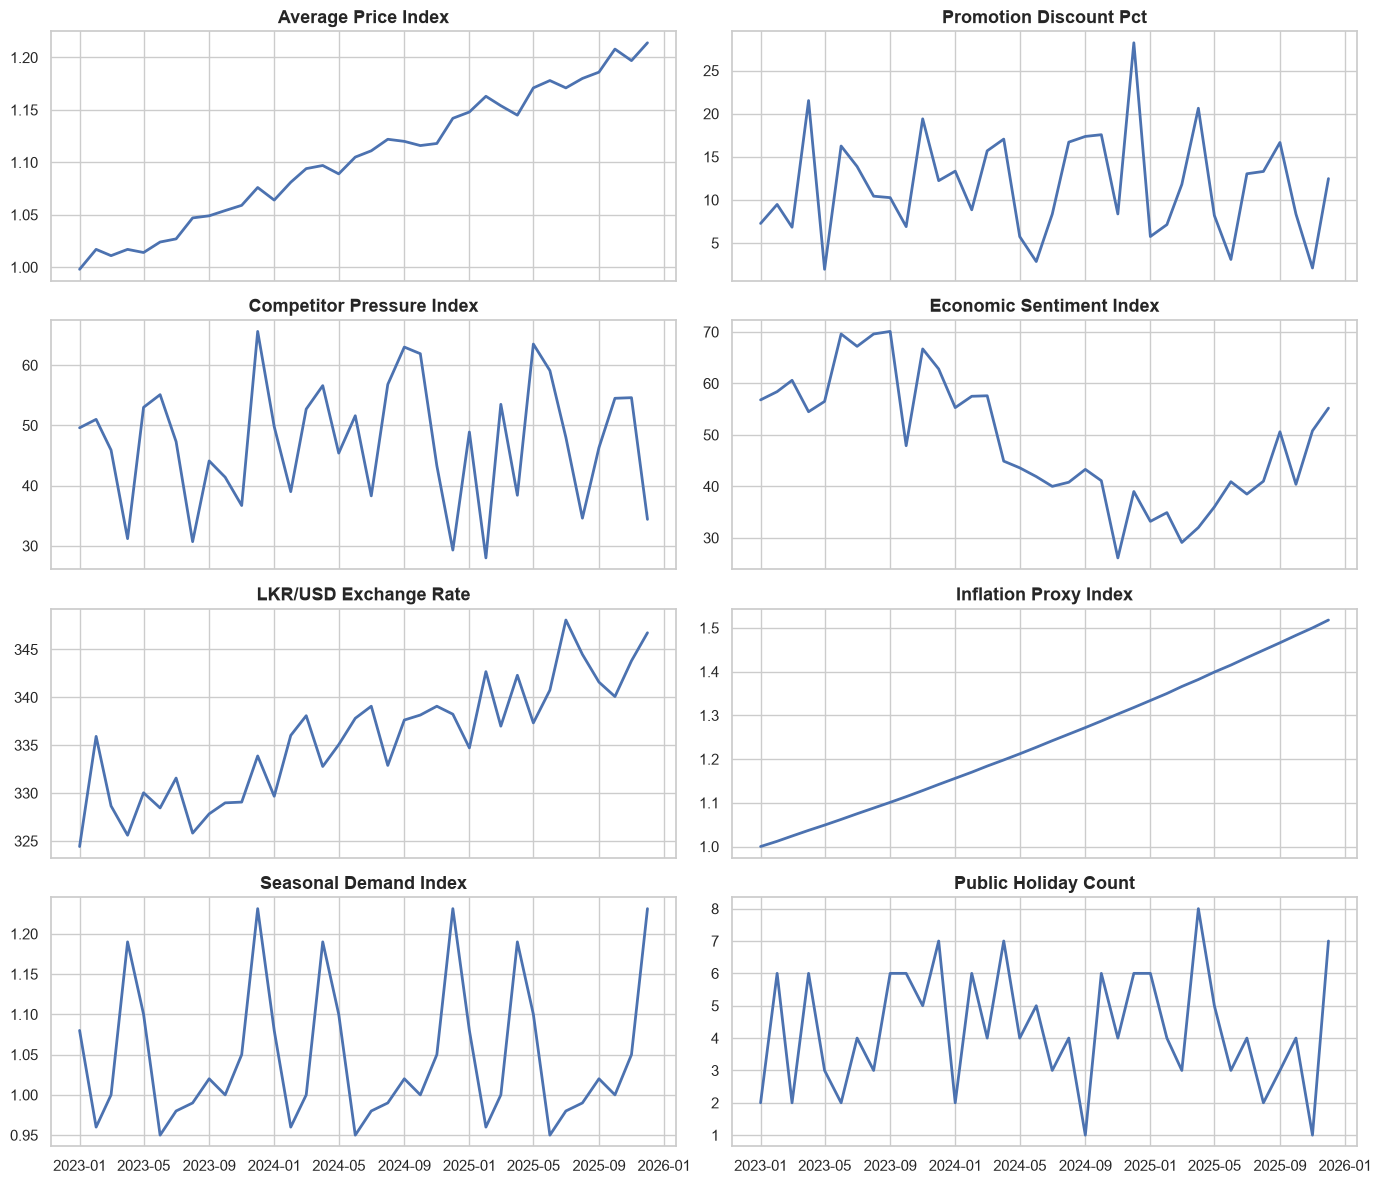

In [ ]:
# external factors over time

fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for ax, f in zip(axes.ravel(), EXTERNAL):
    ax.plot(df[DATE], df[f], lw=2); ax.set_title(NICE[f])
fig.tight_layout(); save(fig, "09_external_trends"); plt.show()

## 8. Seasonality & decomposition
Splits sales into **trend + seasonal + residual**. With only 36 months we have 3 yearly cycles,
so treat the seasonal estimate as indicative, not exact.

saved -> ..\outputs\figures\10_sales_decomposition.png


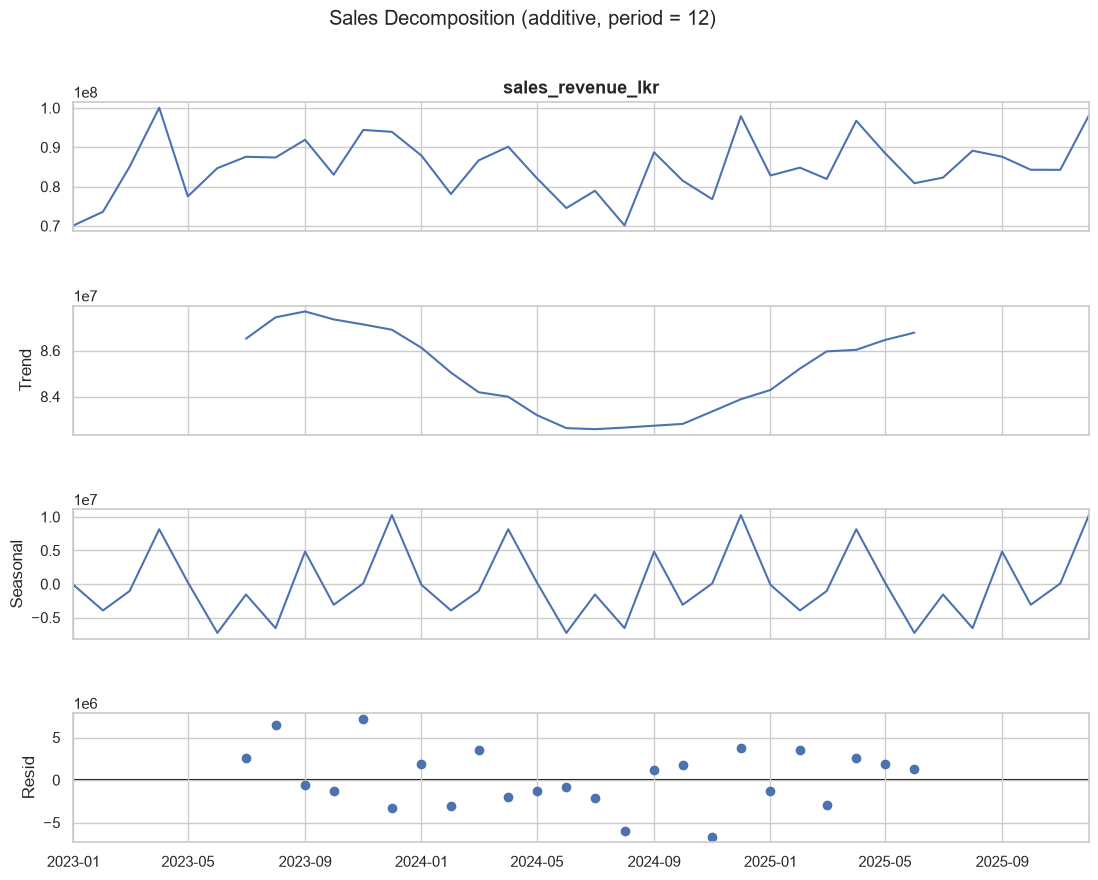

saved -> ..\outputs\figures\11_monthly_seasonality.png


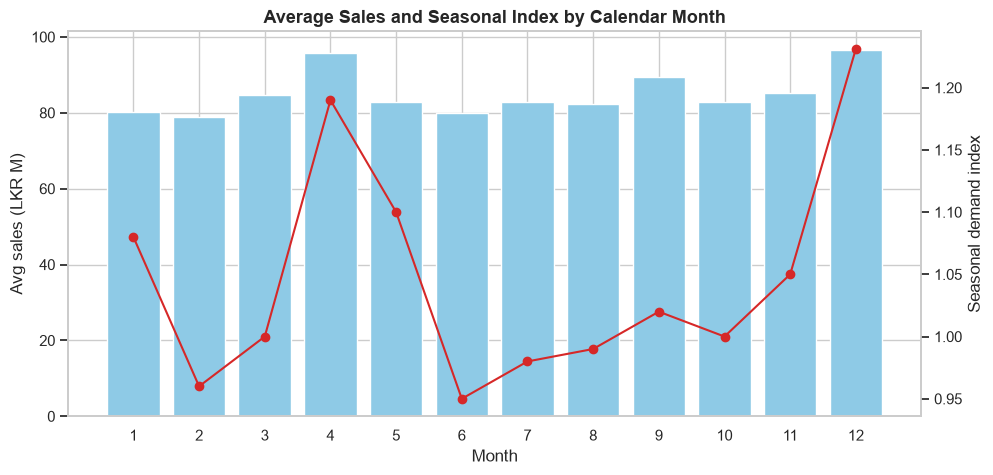

In [ ]:
ts = df.set_index(DATE)[TARGET]
res = seasonal_decompose(ts, model="additive", period=12)
fig = res.plot(); fig.set_size_inches(12, 9); fig.suptitle("Sales Decomposition (additive, period = 12)", y=1.02)
save(fig, "10_sales_decomposition"); plt.show()

# average sales & seasonal index by calendar month

m = df.assign(month_no=df[DATE].dt.month).groupby("month_no").agg(
    avg_sales=(TARGET, "mean"), avg_seasonal_index=("seasonal_demand_index", "mean"))
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(m.index, m.avg_sales / 1e6, color="#8ecae6"); ax1.set(xlabel="Month", ylabel="Avg sales (LKR M)", xticks=range(1, 13))
ax2 = ax1.twinx(); ax2.plot(m.index, m.avg_seasonal_index, color="#d62828", marker="o"); ax2.set_ylabel("Seasonal demand index"); ax2.grid(False)
ax1.set_title("Average Sales and Seasonal Index by Calendar Month")
save(fig, "11_monthly_seasonality"); plt.show()

## 9. Carry-over (lag) check
Does spend this month affect sales in the *following* months? Correlate sales with spend lagged 0–3 months.


saved -> ..\outputs\figures\12_lag_correlation.png


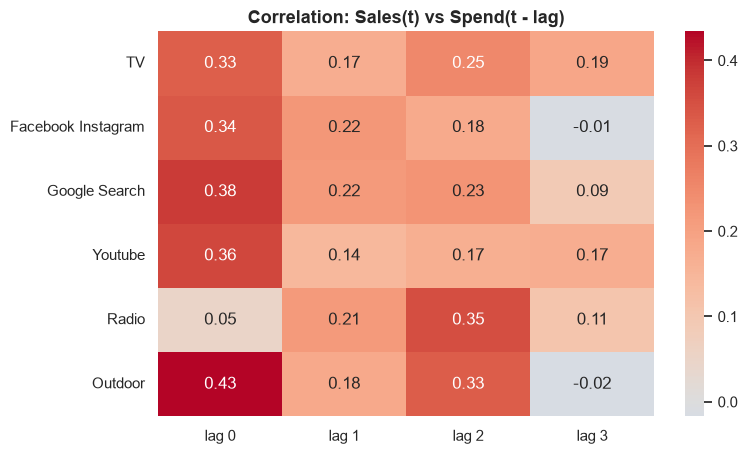

In [13]:
lags = range(0, 4)
lag_tbl = pd.DataFrame({f"lag {k}": [df[TARGET].corr(df[ch].shift(k)) for ch in CHANNELS] for k in lags},
                       index=[NICE[c] for c in CHANNELS])
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(lag_tbl, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation: Sales(t) vs Spend(t - lag)"); save(fig, "12_lag_correlation"); plt.show()

## 10. Engineered features (created in notebook 02)

**Two things to watch**
- `lag_1_total_spend`, `lag_2_total_spend`, `rolling_3_month_spend` contain **0 in the first rows** (no earlier months exist). Those zeros are not real spend, so they are set to NaN here.

- `roas`, `revenue_per_unit`, `revenue_per_conversion` are calculated **from sales revenue** (the target). They are fine for reporting, but must **not** be used as model predictors (data leakage).

lag_1_total_spend: 1 placeholder zero(s) set to NaN
lag_2_total_spend: 2 placeholder zero(s) set to NaN
rolling_3_month_spend: 2 placeholder zero(s) set to NaN
saved -> ..\outputs\figures\13_engineered_corr_with_sales.png


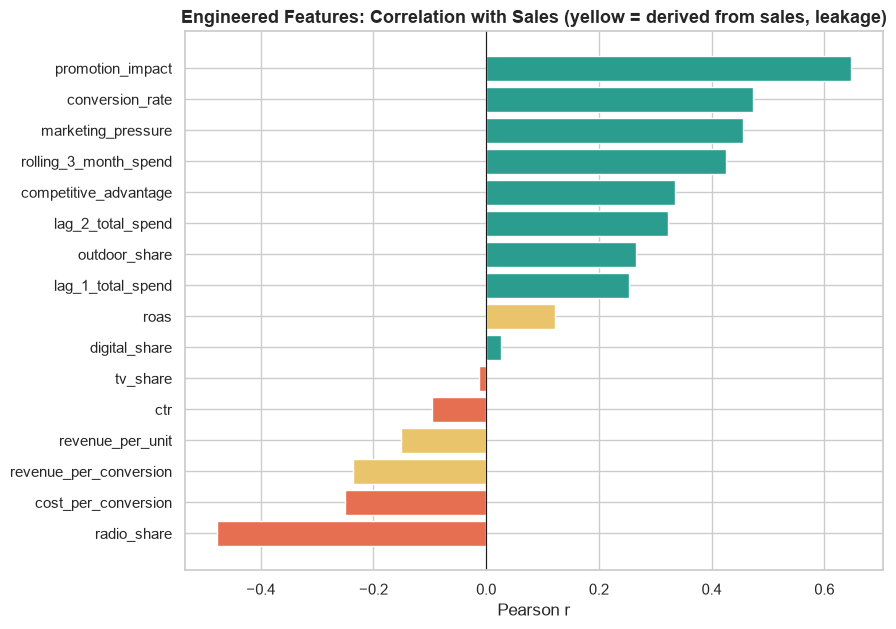

promotion_impact          0.65
conversion_rate           0.47
marketing_pressure        0.46
rolling_3_month_spend     0.43
competitive_advantage     0.33
lag_2_total_spend         0.32
outdoor_share             0.27
lag_1_total_spend         0.25
roas                      0.12
digital_share             0.03
tv_share                 -0.01
ctr                      -0.10
revenue_per_unit         -0.15
revenue_per_conversion   -0.24
cost_per_conversion      -0.25
radio_share              -0.48
Name: sales_revenue_lkr, dtype: float64


In [14]:
ENG = ["tv_share", "digital_share", "radio_share", "outdoor_share", "ctr", "conversion_rate",
       "revenue_per_unit", "revenue_per_conversion", "roas", "cost_per_conversion",
       "lag_1_total_spend", "lag_2_total_spend", "rolling_3_month_spend",
       "marketing_pressure", "competitive_advantage", "promotion_impact"]
ENG = [c for c in ENG if c in df.columns]
LEAKY = [c for c in ["roas", "revenue_per_unit", "revenue_per_conversion"] if c in ENG]

eng = df.copy()
for c in ["lag_1_total_spend", "lag_2_total_spend", "rolling_3_month_spend"]:
    if c in eng.columns:
        n_zero = int((eng[c] == 0).sum())
        eng.loc[eng[c] == 0, c] = np.nan
        print(f"{c}: {n_zero} placeholder zero(s) set to NaN")

ec = eng[ENG + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#e9c46a" if i in LEAKY else ("#2a9d8f" if v > 0 else "#e76f51") for i, v in ec.items()]
ax.barh(ec.index, ec.values, color=colors); ax.axvline(0, color="k", lw=0.8)
ax.set(title="Engineered Features: Correlation with Sales (yellow = derived from sales, leakage)", xlabel="Pearson r")
save(fig, "13_engineered_corr_with_sales"); plt.show()
print(ec.sort_values(ascending=False).round(2))

saved -> ..\outputs\figures\14_roas_trend.png


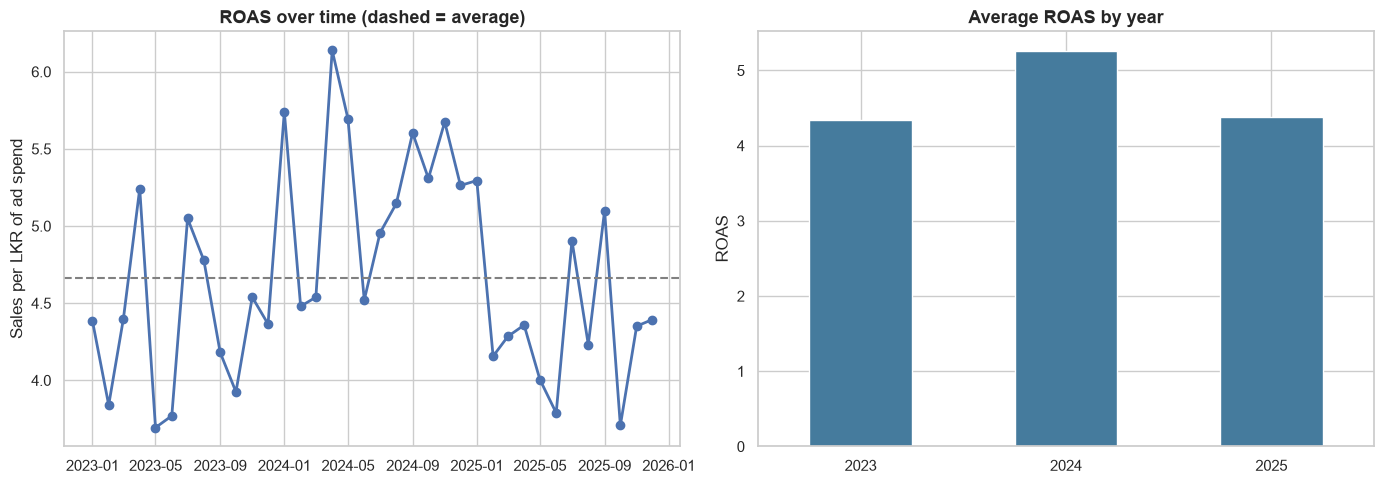

In [ ]:
# ROAS (sales / spend) over time and by year - a quick efficiency view

if "roas" in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(df[DATE], df["roas"], marker="o", lw=2); axes[0].axhline(df["roas"].mean(), ls="--", color="grey")
    axes[0].set(title="ROAS over time (dashed = average)", ylabel="Sales per LKR of ad spend")
    df.groupby(df[DATE].dt.year)["roas"].mean().plot(kind="bar", ax=axes[1], color="#457b9d", rot=0)
    axes[1].set(title="Average ROAS by year", xlabel="", ylabel="ROAS")
    fig.tight_layout(); save(fig, "14_roas_trend"); plt.show()

## 11. Multicollinearity – VIF
VIF > 5 = moderate, **VIF > 10 = high** .
We exclude `total_ad_spend` (it is the sum of channels) and outcome-like columns (units, impressions, clicks, conversions).

In [16]:
feat = CHANNELS + EXTERNAL
X = add_constant(df[feat])
vif = pd.DataFrame({"feature": feat,
                    "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(feat))]})
vif["flag"] = pd.cut(vif["VIF"], [0, 5, 10, np.inf], labels=["OK", "moderate", "HIGH"])
vif = vif.sort_values("VIF", ascending=False).round(2)
vif.to_csv(TAB / "vif_table.csv", index=False)
vif

,feature,VIF,flag
11,inflation_proxy_index,104.79,HIGH
6,average_price_index,93.33,HIGH
10,lkr_usd_exchange_rate,7.18,moderate
5,outdoor_spend_lkr,2.93,OK
3,youtube_spend_lkr,2.73,OK
2,google_search_spend_lkr,2.60,OK
9,economic_sentiment_index_0_100,2.56,OK
4,radio_spend_lkr,2.48,OK
1,facebook_instagram_spend_lkr,2.41,OK
0,tv_spend_lkr,2.39,OK


## 12. Outliers

Observations with |z| > 2.5:
none
saved -> ..\outputs\figures\15_outliers_boxplots.png


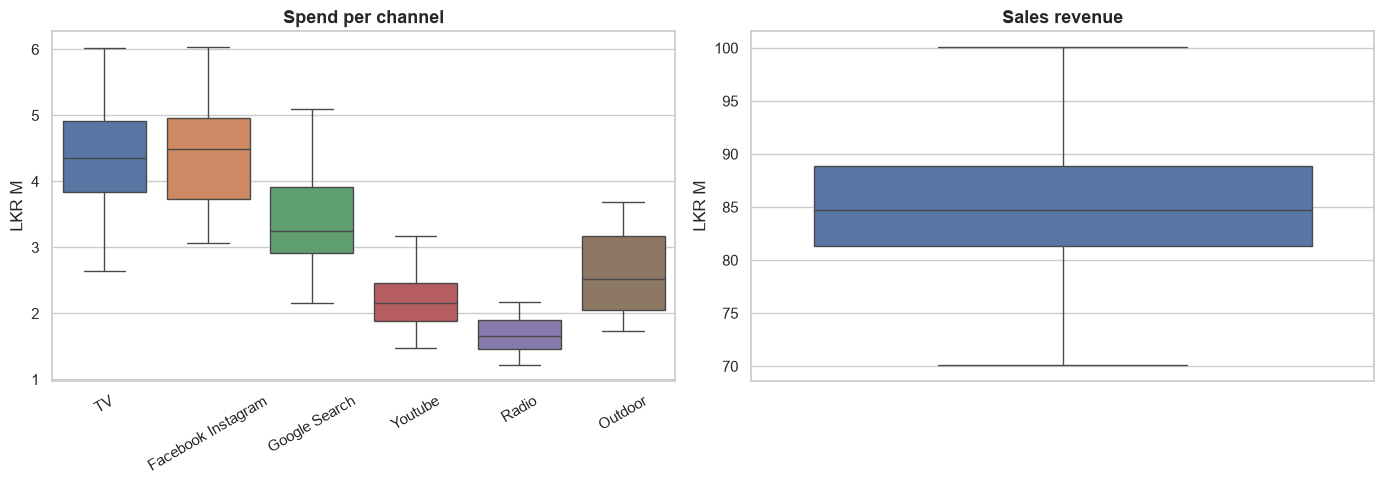

In [17]:
z = (df[CHANNELS + [TARGET]] - df[CHANNELS + [TARGET]].mean()) / df[CHANNELS + [TARGET]].std()
out = z.abs().stack().loc[lambda s: s > 2.5].rename("abs_z").reset_index()
out.columns = ["row", "variable", "abs_z"]; out["month"] = out["row"].map(df[DATE].dt.date)
print("Observations with |z| > 2.5:"); print(out.round(2).to_string(index=False) if len(out) else "none")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df[CHANNELS].div(1e6).rename(columns=NICE), ax=axes[0]); axes[0].set(title="Spend per channel", ylabel="LKR M"); axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(y=df[TARGET] / 1e6, ax=axes[1]); axes[1].set(title="Sales revenue", ylabel="LKR M")
fig.tight_layout(); save(fig, "15_outliers_boxplots"); plt.show()

## 13. Auto-summary 

In [18]:
sc = corr[TARGET].drop(TARGET)
print("Sales trend      : first 12m -> last 12m change = %.1f%%" %
      ((df[TARGET].tail(12).sum() / df[TARGET].head(12).sum() - 1) * 100))
print("Peak month       :", df.loc[df[TARGET].idxmax(), DATE].strftime("%b %Y"))
print("Biggest channel  : %s (%.1f%% of spend)" % (NICE[share.index[0]], share.iloc[0]))
print("Smallest channel : %s (%.1f%% of spend)" % (NICE[share.index[-1]], share.iloc[-1]))
print("Top correlates   :", ", ".join(f"{NICE[i]} ({sc[i]:+.2f})" for i in sc.abs().sort_values(ascending=False).index[:4]))
best_ch = df[CHANNELS].corrwith(df[TARGET]).idxmax()
print("Best channel r   : %s (%.2f)" % (NICE[best_ch], df[CHANNELS].corrwith(df[TARGET]).max()))
print("High-VIF features:", vif.loc[vif.VIF > 10, "feature"].tolist() or "none above 10")

Sales trend      : first 12m -> last 12m change = 1.2%
Peak month       : Apr 2023
Biggest channel  : Facebook Instagram (23.7% of spend)
Smallest channel : Radio (9.0% of spend)
Top correlates   : Seasonal Demand Index (+0.62), Promotion Discount Pct (+0.58), Outdoor (+0.43), Google Search (+0.38)
Best channel r   : Outdoor (0.43)
High-VIF features: ['inflation_proxy_index', 'average_price_index']
